# Quantum Lab 2: Advanced Multi-Qubit Entanglement
## Author: Lyberius Ennio F. Taruc
## Created: 02 November 2026

### Step 0: Initial Setup (Installation of Libraries)

In [1]:
!pip install -U "numpy>=2.0,<2.8" "contourpy>=1.3" "matplotlib>=3.9" qiskit qiskit-aer pylatexenc charset_normalizer


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


### Step 0: Call needed Python Libraries (Including _Qiskit_)

In [3]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import Aer
from qiskit.visualization import plot_histogram, plot_bloch_vector, plot_bloch_multivector
import numpy as np

### Step 01: Task 2.1 — 3-Qubit GHZ State

The natural 3-qubit generalization of a Bell state is the GHZ state — one Hadamard, then a chain of CNOTs linking every qubit to the first.

Check: confirm only 000 and 111 appear (within normal shot noise) — if anything else shows up, something's wrong with the circuit, not with quantum mechanics.

{'111': 507, '000': 493}


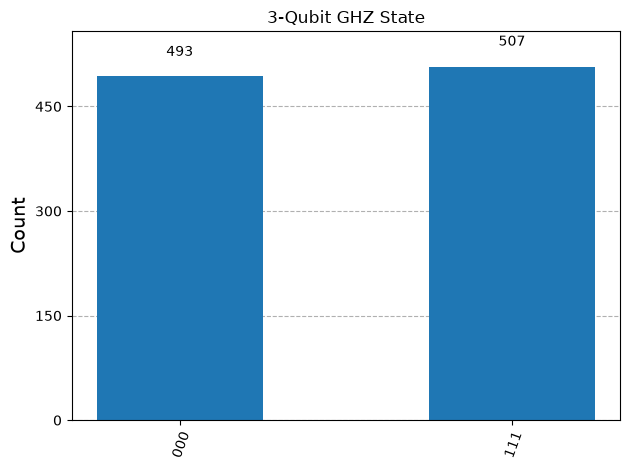

In [4]:
qc_ghz3 = QuantumCircuit(3)
qc_ghz3.h(0)
qc_ghz3.cx(0, 1)
qc_ghz3.cx(1, 2)
qc_ghz3.measure_all()

# Run a simulation
simulator = Aer.get_backend('aer_simulator')
result = simulator.run(qc_ghz3).result()
statevector_sim = Aer.get_backend('statevector_simulator')

compiled = transpile(qc_ghz3, simulator)
ghz3_counts = simulator.run(compiled, shots=1000).result().get_counts()
print(ghz3_counts)
plot_histogram(ghz3_counts, title="3-Qubit GHZ State")
# Example output: {'111': 494, '000': 506}

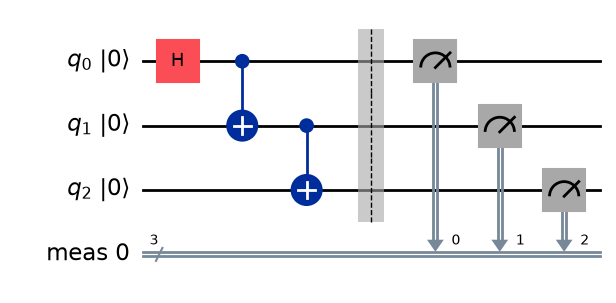

In [5]:
# Draw circuit
qc_ghz3.draw(output="mpl", initial_state=True)

### Step 02: Task 2.2 — 4-Qubit Entangled System
Extend the same pattern to 4 qubits: one more CNOT, chaining qubit 3 onto qubit 2.

Compare with Task 2.1: Which two outcomes dominate here, and how does that compare to the 3-qubit case? (Hint: it is the same pattern, just one digit longer — tie this back to the state space growth: both states only ever occupy 2 of the available basis states, regardless of how large the system gets.)

{'1111': 505, '0000': 495}


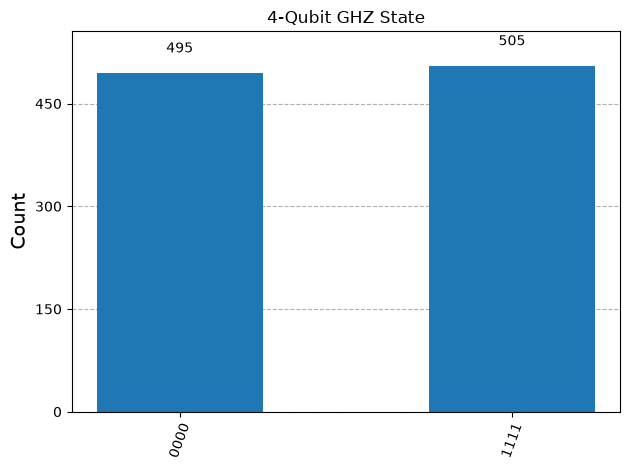

In [6]:
qc_ghz4 = QuantumCircuit(4)
qc_ghz4.h(0)
qc_ghz4.cx(0, 1)
qc_ghz4.cx(1, 2)
qc_ghz4.cx(2, 3)
qc_ghz4.measure_all()

compiled = transpile(qc_ghz4, simulator)
ghz4_counts = simulator.run(compiled, shots=1000).result().get_counts()
print(ghz4_counts)
plot_histogram(ghz4_counts, title="4-Qubit GHZ State")
# Example output: {'0000': 513, '1111': 487}

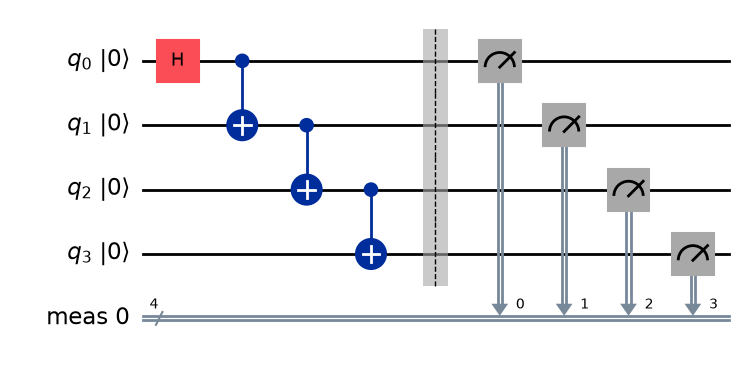

In [7]:
# Draw circuit
qc_ghz4.draw(output="mpl", initial_state=True)

### Step 03: Task 2.3 — Partial Entanglement
Take the 4-qubit circuit and remove one CNOT — qubit 3 is left completely untouched, so it's never linked to the rest.

{'0000': 517, '0111': 483}


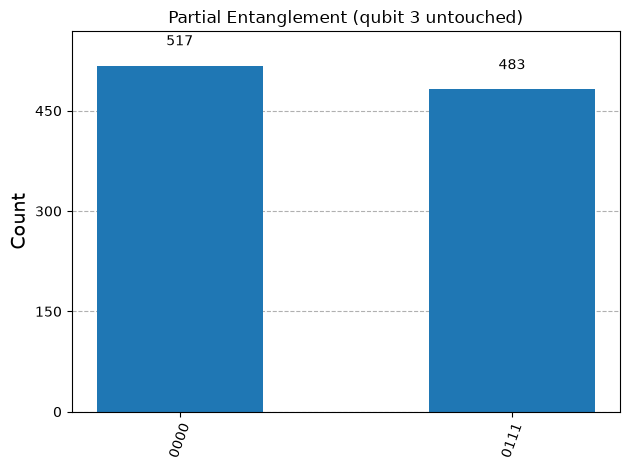

In [7]:
qc_partial = QuantumCircuit(4)
qc_partial.h(0)
qc_partial.cx(0, 1)
qc_partial.cx(1, 2)
# qc_partial.cx(2, 3)  <- removed: qubit 3 is never entangled with the others
qc_partial.measure_all()

compiled = transpile(qc_partial, simulator)
partial_counts = simulator.run(compiled, shots=1000).result().get_counts()
print(partial_counts)
plot_histogram(partial_counts, title="Partial Entanglement (qubit 3 untouched)")
# Example output: {'0000': 481, '0111': 519}

Compare with Task 2.2: Qubit 3 is the leftmost digit in each outcome (following the standard bit-ordering convention). What value does it always take, and why — given it starts in state |0⟩ and no gate acts on it?

### Step 04: Task 2.4 — Measurement Variation

Go back to the 3-qubit GHZ circuit, but this time measure only one qubit instead of all three. The cell below measures qubit 0 only — after running it, copy the cell and repeat for qubit 1, then qubit 2, changing just the qubit index in .measure(?, 0).

{'0': 514, '1': 486}


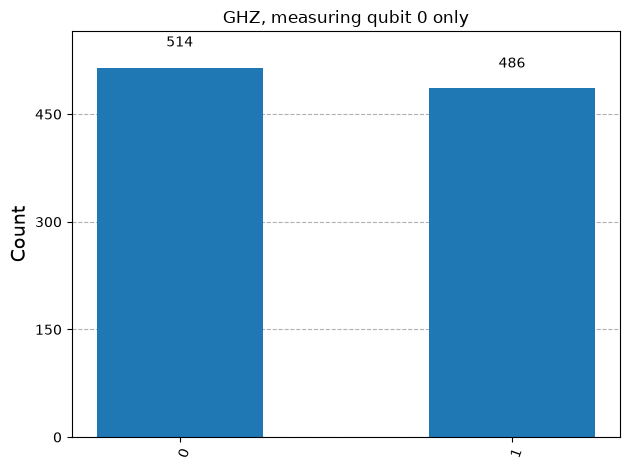

In [8]:
qc_single = QuantumCircuit(3, 1)
qc_single.h(0)
qc_single.cx(0, 1)
qc_single.cx(1, 2)
qc_single.measure(0, 0)   # <- try changing this 0 to 1, then to 2, in copies of this cell

compiled = transpile(qc_single, simulator)
single_counts = simulator.run(compiled, shots=1000).result().get_counts()
print(single_counts)
plot_histogram(single_counts, title="GHZ, measuring qubit 0 only")
# Example output: {'0': 506, '1': 494}

{'1': 484, '0': 516}


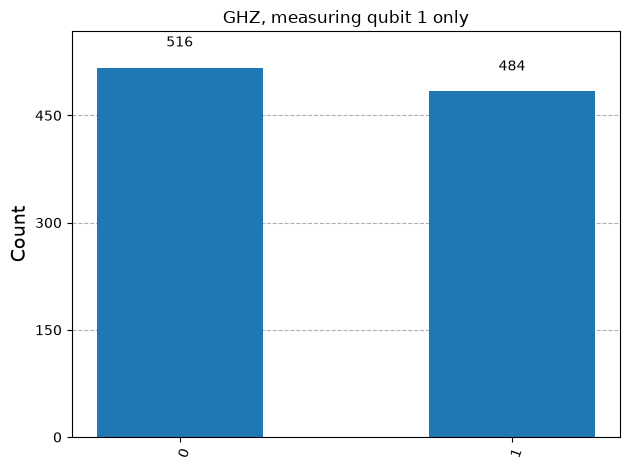

In [14]:
# Your copy for qubit 1 -- measure(1, 0)
qc_single.measure(1, 0) 
plot_histogram(single_counts, title="GHZ, measuring qubit 1 only")

compiled = transpile(qc_single, simulator)
single_counts = simulator.run(compiled, shots=1000).result().get_counts()
print(single_counts)
plot_histogram(single_counts, title="GHZ, measuring qubit 1 only")


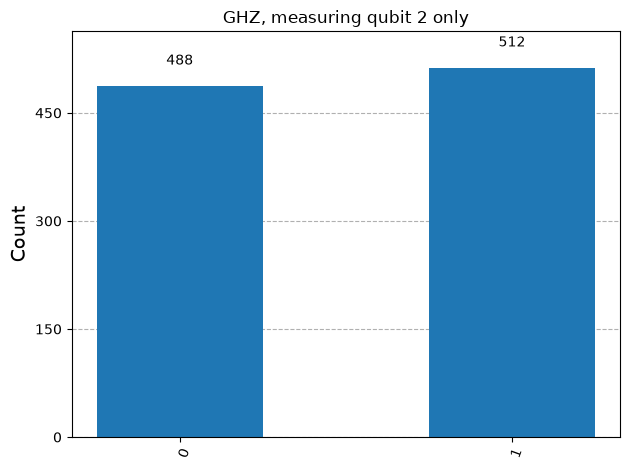

In [14]:
# Your copy for qubit 2 -- measure(2, 0)
qc_single.measure(2, 2) 

plot_histogram(single_counts, title="GHZ, measuring qubit 2 only")

Question: all three single-qubit measurements should come out roughly 50/50. On their own, does that prove the qubits are entangled? What would prove it? (Hint: think about what happens if you measure two qubits together, in the same run, instead of one at a time.)

### Step 04: Task 2.5 — Controlled Rotation (Advanced)

Replace the Hadamard with a partial rotation, ry(π/3), which creates an unequal superposition instead of a 50/50 one — then chain the same CNOTs as before.

Compare with Task 2.1: Are 000 and 111 still the only two outcomes? Are they still equally likely? If not, why not? Think back to state amplitudes and probabilities: ry(π/3) does not split amplitude evenly between |0⟩ and |1⟩ the way a Hadamard gate does, so squaring those unequal amplitudes gives unequal measurement probabilities.

{'111': 251, '000': 749}


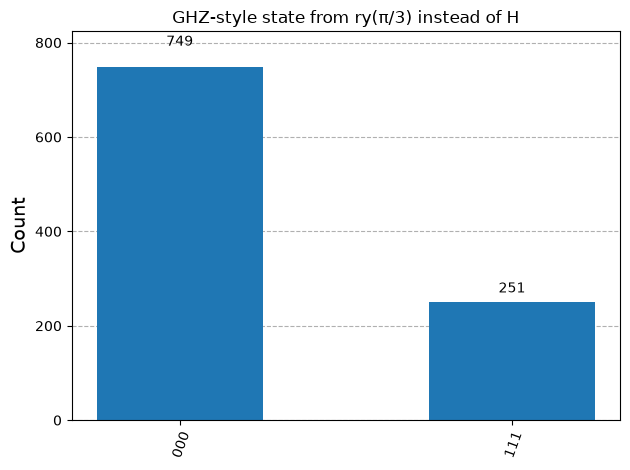

In [15]:
qc_rotation = QuantumCircuit(3)
qc_rotation.ry(np.pi / 3, 0)
qc_rotation.cx(0, 1)
qc_rotation.cx(1, 2)
qc_rotation.measure_all()

compiled = transpile(qc_rotation, simulator)
rotation_counts = simulator.run(compiled, shots=1000).result().get_counts()
print(rotation_counts)
plot_histogram(rotation_counts, title="GHZ-style state from ry(π/3) instead of H")
# Example output: {'000': 754, '111': 246}